In [31]:
# Python libraries used in this notebook
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss, log_loss,
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score
)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Comparative Statistical Modelling and Validation of Credit Default Risk

## Logistic Regression, Probit Regression and Decision Tree Comparison

**Final Exam Project**  
**Course:** Math Concepts for Developers  
**Author:** Karamfila Stoykova  
**Date:** 31 October 2026

## Abstract

This project explores the relationship between borrower characteristics and credit default using a synthetic dataset. The analysis begins with descriptive statistics and compares borrowers who defaulted with those who did not. Non-parametric statistical tests and effect size measures are used to identify and assess differences between the two groups.

The project then develops and compares four predictive models: a single-variable logistic regression, a multivariable logistic regression, a probit model, and a simple decision tree. A separate part of the analysis focuses on logistic regression, where the maximum likelihood estimation process is implemented manually using the Newton-Raphson algorithm. The results are then compared with those obtained from the scikit-learn implementation.

Model performance is evaluated on a separate test dataset using ROC AUC, Brier score, log loss, confusion matrices, and calibration across different risk groups. To assess model stability, five-fold stratified cross-validation is also performed. Since the data are synthetic, the true probability of default is known for every borrower, allowing the predicted probabilities to be compared directly with the actual values.

The dataset was created solely for educational purposes. Therefore, the results should not be interpreted as representing a real financial institution, a real credit portfolio, or a production credit risk model.

## Table of Contents

1. Introduction
2. Synthetic Sample Generation
3. Exploratory Statistical Analysis
4. Statistical Modelling Theory
5. Model Development
6. Model Validation and Comparison
7. Results and Model Selection
8. Limitations
9. Conclusion
10. References
11. Self-Assessment

## 1. Introduction

### 1.1 Problem Statement

Credit default is a binary outcome, meaning that a borrower either defaults or does not default during the observation period. The main goal of this project is to examine how different borrower characteristics are related to default risk and to assess whether more advanced models can provide better predictions than a simple benchmark model.

### 1.2 Objectives

The objectives of this project are to:

- create a reproducible synthetic dataset of borrowers;
- explore and describe the main characteristics of the data;
- compare defaulted and non-defaulted borrowers using statistical tests and effect size measures;
- implement the maximum likelihood estimation of logistic regression from scratch;
- develop and evaluate logistic and probit regression models;
- compare these models with a simple decision tree;
- assess model performance in terms of predictive accuracy, calibration, and potential overfitting;
- compare predicted probabilities with the known true probabilities of default;
- interpret the results and discuss the strengths and limitations of each model.

### 1.3 Research Questions

This project aims to answer the following questions:

1. Which borrower characteristics show the largest differences between defaulted and non-defaulted borrowers?
2. Does a multivariable logistic regression perform better than a model based on a single predictor?
3. Are there meaningful differences between the predictions produced by logistic and probit regression?
4. Can a simple decision tree improve prediction accuracy by capturing nonlinear relationships?
5. Which model offers the best balance between predictive performance, calibration, and interpretability?

### 1.4 Hypotheses

It is expected that the multivariable logistic regression will perform better than the DTI-only model because it uses information from several borrower characteristics rather than a single risk factor. The probit model is expected to achieve similar results, as both approaches are based on closely related probability functions. The decision tree may identify nonlinear patterns that are not captured by the regression models, although its probability estimates could be less stable and less well calibrated.

### 1.5 Alternative Modelling Approaches

Several methods can be used to predict a binary outcome such as credit default. Each approach has its own strengths and weaknesses, and some are easier to interpret than others.

**Logistic regression** is one of the most widely used models for binary classification problems. It estimates the probability of default based on borrower characteristics and provides results that are easy to interpret through coefficients and odds ratios. However, it assumes a linear relationship between the predictors and the log-odds of default, which means that nonlinear effects need to be added explicitly.

**Probit regression** is very similar to logistic regression but uses a different probability function based on the standard normal distribution. In practice, the two models often produce similar results. The main reason for including the probit model in this project is to compare its performance with logistic regression and check whether the choice of link function has a noticeable impact on the predictions.

**Decision trees** classify borrowers by applying a sequence of simple decision rules. For example, a borrower may be assigned to a higher-risk group if the debt-to-income ratio exceeds a certain threshold. Unlike regression models, decision trees can naturally capture nonlinear relationships and interactions between variables. However, they can also be sensitive to the data used for training and may overfit if they become too complex. To keep the model simple and interpretable, the decision tree in this project is limited to a maximum depth of three levels and a minimum of 80 observations in each terminal node.

**More advanced machine learning methods**, such as random forests, gradient boosting, and neural networks, are not included in this project. While these methods can sometimes achieve higher predictive accuracy, they are often more difficult to interpret. Since the main objective of this study is to demonstrate and compare statistical modelling and validation techniques, the focus is placed on methods whose assumptions and results can be explained clearly.

## 2. Synthetic Sample Generation

### 2.1 Variables

| Variable | Description |
|---|---|
| `age` | Borrower age in years |
| `monthly_income` | Monthly disposable income |
| `loan_amount` | Outstanding loan amount |
| `dti` | Debt-to-income ratio |
| `credit_utilisation` | Utilised share of available revolving credit |
| `delinquencies_12m` | Number of recent delinquency events |
| `default_flag` | Binary outcome: 1 default, 0 non-default |

### 2.2 Data-Generating Process

Because real borrower data were not available, a synthetic dataset was created for the analysis. The generated variables were designed to resemble common characteristics observed in consumer lending portfolios.

The explanatory variables were generated from the following probability distributions:

| Variable | Distribution |
|---|---|
| Age $A_i$ | $\mathcal{N}(42,\,11^2)$, rounded and clipped to $[18, 75]$ |
| Income $I_i$ | $\text{LogNormal}(\ln 2600,\,0.42^2)$, clipped to $[800, 12000]$ |
| Loan amount | $\text{LogNormal}(\ln 18000,\,0.65^2)$, clipped to $[1000, 150000]$ |
| DTI | $\text{Beta}(2.4,\,4.2)$ |
| Utilisation $U_i$ | $\text{Beta}(2.0,\,2.7)$ |
| Delinquencies $D_i$ | $\text{Binomial}\big(3,\;\min(0.03+0.16\,DTI_i+0.14\,U_i,\;0.5)\big)$ |

The binary outcome is generated from a logistic probability:

$$p_i=P(Y_i=1\mid X_i)=\frac{1}{1+e^{-z_i}}, \qquad Y_i\sim\text{Bernoulli}(p_i)$$

with the latent risk score

$$z_i=-4.10+2.20\,DTI_i+1.45\,U_i+0.70\,D_i-0.35\,\tilde I_i+0.10\,\tilde A_i+1.35\,DTI_i U_i+0.18\,\min(LB_i,4)^2$$

where $\tilde I_i$ is the standardised logarithm of income, $\tilde A_i$ is standardised age and

$$LB_i=\frac{\text{loan amount}_i}{12\cdot I_i}$$

is the loan burden expressed in years of income.

The interaction term $DTI_i U_i$ makes the effect of DTI stronger at high utilisation, and the quadratic loan-burden term introduces a mild nonlinearity. Neither term is included in the linear models estimated later, so these models are deliberately *misspecified*. This gives the decision tree a realistic opportunity to detect structure that the linear models cannot represent. Because the probabilities $p_i$ are known, they are stored as `true_pd` and used in Section 6.2 as a ground truth.


In [32]:
# Global settings used throughout the notebook
RANDOM_SEED = 42          # fixed seed for full reproducibility
N_BORROWERS = 5000        # size of the synthetic sample
TEST_SIZE = 0.30          # share of observations kept for independent testing
THRESHOLD = 0.30          # illustrative probability cut-off for classification
N_FOLDS = 5               # number of cross-validation folds

FEATURES = ['age', 'monthly_income', 'loan_amount', 'dti',
            'credit_utilisation', 'delinquencies_12m']
TARGET = 'default_flag'

In [33]:
def standardise(values: np.ndarray) -> np.ndarray:
    # Return (x - mean) / standard deviation.
    return (values - values.mean()) / values.std()


def generate_sample(n: int, seed: int) -> pd.DataFrame:
    # Generate a synthetic borrower sample following the process in Section 2.2.
    #
    # Returns a DataFrame with the borrower features, the true probability of
    # default (`true_pd`) and the simulated binary outcome (`default_flag`).
    rng = np.random.default_rng(seed)

    age = np.clip(np.rint(rng.normal(42, 11, n)), 18, 75).astype(int)
    monthly_income = np.clip(rng.lognormal(np.log(2600), 0.42, n), 800, 12000)
    loan_amount = np.clip(rng.lognormal(np.log(18000), 0.65, n), 1000, 150000)
    dti = rng.beta(2.4, 4.2, n)
    credit_utilisation = rng.beta(2.0, 2.7, n)

    delinquency_p = np.clip(0.03 + 0.16 * dti + 0.14 * credit_utilisation, 0, 0.50)
    delinquencies_12m = rng.binomial(3, delinquency_p, n)

    income_z = standardise(np.log(monthly_income))
    age_z = standardise(age)
    loan_burden = loan_amount / (12 * monthly_income)

    z = (
        -4.10
        + 2.20 * dti
        + 1.45 * credit_utilisation
        + 0.70 * delinquencies_12m
        - 0.35 * income_z
        + 0.10 * age_z
        + 1.35 * dti * credit_utilisation
        + 0.18 * np.minimum(loan_burden, 4) ** 2
    )
    true_pd = 1 / (1 + np.exp(-z))
    default_flag = rng.binomial(1, true_pd, n)

    return pd.DataFrame({
        'age': age,
        'monthly_income': monthly_income,
        'loan_amount': loan_amount,
        'dti': dti,
        'credit_utilisation': credit_utilisation,
        'delinquencies_12m': delinquencies_12m,
        'true_pd': true_pd,
        TARGET: default_flag,
    })

In [34]:
data = generate_sample(N_BORROWERS, RANDOM_SEED)

print('Sample shape:', data.shape)
print(f'Default rate: {data[TARGET].mean():.2%}')
print(f'Average true PD: {data["true_pd"].mean():.2%}')
data.head()

Sample shape: (5000, 8)
Default rate: 15.82%
Average true PD: 15.89%


,age,monthly_income,loan_amount,dti,credit_utilisation,delinquencies_12m,true_pd,default_flag
0,45,2333.038665,20185.243772,0.401193,0.276260,0,0.079082,0
1,31,2292.693600,32291.434926,0.365250,0.278803,1,0.141509,0
2,50,1940.439089,6912.945807,0.225580,0.419096,0,0.073403,0
3,52,3112.649445,14953.239306,0.411355,0.351308,0,0.074717,0
4,21,2869.284926,30855.696964,0.343195,0.320391,2,0.188319,0


In [35]:
# Data-quality checks
checks = pd.Series({
    'No missing values': not data.isna().any().any(),
    'No duplicate rows': not data.duplicated().any(),
    'Age in expected range': data['age'].between(18, 75).all(),
    'Positive income': (data['monthly_income'] > 0).all(),
    'Positive loan amount': (data['loan_amount'] > 0).all(),
    'DTI in [0, 1]': data['dti'].between(0, 1).all(),
    'Utilisation in [0, 1]': data['credit_utilisation'].between(0, 1).all(),
    'Binary target': data[TARGET].isin([0, 1]).all(),
})
assert checks.all(), 'At least one data-quality check failed.'
checks

No missing values        True
No duplicate rows        True
Age in expected range    True
Positive income          True
Positive loan amount     True
DTI in [0, 1]            True
Utilisation in [0, 1]    True
Binary target            True
dtype: bool

## 3. Exploratory Statistical Analysis

Before developing the predictive models, the dataset is explored to better understand the characteristics of the borrowers and the factors that may be associated with credit default. The analysis compares defaulted and non-defaulted borrowers and examines relationships among the main explanatory variables. The variable true_pd is not included because, in practice, the true probability of default is unknown and cannot be observed.

In [36]:
data[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,5000.0,41.843,10.838,18.000,34.000,42.000,49.000,75.000
monthly_income,5000.0,2845.377,1265.061,800.000,1969.183,2578.191,3448.284,12000.000
loan_amount,5000.0,22150.130,16143.938,1438.066,11564.561,17628.257,27687.206,150000.000
dti,5000.0,0.362,0.176,0.009,0.225,0.346,0.486,0.920
credit_utilisation,5000.0,0.421,0.206,0.001,0.258,0.407,0.568,0.992
delinquencies_12m,5000.0,0.453,0.623,0.000,0.000,0.000,1.000,3.000


In [37]:
group_comparison = data.groupby(TARGET)[FEATURES].agg(['mean', 'median', 'std']).T
group_comparison.round(3)

default_flag                       0          1
age                mean       41.624     43.008
                   median     42.000     43.000
                   std        10.803     10.955
monthly_income     mean     2923.429   2430.053
                   median   2637.627   2250.605
                   std      1281.783   1081.839
loan_amount        mean    21424.179  26012.996
                   median  17303.859  19207.392
                   std     15208.626  19985.174
dti                mean        0.349      0.432
                   median      0.335      0.435
                   std         0.173      0.180
credit_utilisation mean        0.405      0.502
                   median      0.391      0.508
                   std         0.202      0.208
delinquencies_12m  mean        0.402      0.724
                   median      0.000      1.000
                   std         0.585      0.741

### 3.1 Statistical Tests and Effect Sizes

Descriptive statistics provide an initial overview of the data, but they do not indicate whether the observed differences between defaulted and non-defaulted borrowers are statistically meaningful. To evaluate these differences, the Mann-Whitney U test is applied to each variable. This non-parametric test does not require the data to follow a normal distribution and is therefore suitable for variables such as income and loan amount, which are often skewed.

The null hypothesis of the test states that the distributions of the two groups are the same.

Because the dataset contains 5,000 observations, even relatively small differences may appear statistically significant. For this reason, statistical significance is complemented by a measure of practical significance using Cohen's d, which quantifies the magnitude of the difference between the two groups:

$$d=\frac{\bar x_1-\bar x_0}{s_p},\qquad s_p=\sqrt{\frac{(n_1-1)s_1^2+(n_0-1)s_0^2}{n_1+n_0-2}}$$

where index 1 refers to defaulted borrowers and index 0 refers to non-defaulted borrowers. As a general guideline, values of approximately $|d|=0.2$, $0.5$, and $0.8$ are often interpreted as small, medium, and large effects, respectively.

In [38]:
def cohens_d(group_1: pd.Series, group_0: pd.Series) -> float:
    # Standardised mean difference with a pooled standard deviation.
    n1, n0 = len(group_1), len(group_0)
    pooled_var = ((n1 - 1) * group_1.var() + (n0 - 1) * group_0.var()) / (n1 + n0 - 2)
    return (group_1.mean() - group_0.mean()) / np.sqrt(pooled_var)


defaulted = data[data[TARGET] == 1]
non_defaulted = data[data[TARGET] == 0]

test_rows = []
for feature in FEATURES:
    u_stat, p_value = stats.mannwhitneyu(defaulted[feature], non_defaulted[feature],
                                         alternative='two-sided')
    test_rows.append({
        'Variable': feature,
        'Mean (default)': defaulted[feature].mean(),
        'Mean (non-default)': non_defaulted[feature].mean(),
        'Mann-Whitney p-value': p_value,
        "Cohen's d": cohens_d(defaulted[feature], non_defaulted[feature]),
    })

group_tests = (pd.DataFrame(test_rows)
               .set_index('Variable')
               .sort_values("Cohen's d", key=np.abs, ascending=False))
group_tests.round(4)

,Mean (default),Mean (non-default),Mann-Whitney p-value,Cohen's d
Variable,,,,
delinquencies_12m,0.7244,0.4025,0.0000,0.5260
dti,0.4324,0.3485,0.0000,0.4825
credit_utilisation,0.5024,0.4052,0.0000,0.4783
monthly_income,2430.0528,2923.4291,0.0000,-0.3940
loan_amount,26012.9960,21424.1789,0.0000,0.2858
age,43.0076,41.6237,0.0007,0.1278


**Interpretation.** All six variables show statistically significant differences between defaulted and non-defaulted borrowers. However, with a sample of 5,000 observations, statistical significance alone is not enough to judge the importance of a result. For this reason, greater attention is given to the effect sizes.

The largest differences are observed for delinquency events ($d=0.53$), debt-to-income ratio ($d=0.48$), and credit utilisation ($d=0.48$), all of which indicate medium effects. Monthly income shows a smaller negative effect ($d=-0.39$), while loan amount has a relatively small effect ($d=0.29$). Age has the weakest relationship with default ($d=0.13$), suggesting only a minor difference between the two groups.

Overall, these results are consistent with the way the synthetic dataset was generated. Variables such as DTI, utilisation, and delinquencies were designed to have a stronger influence on default risk, whereas age was assigned a much smaller role.

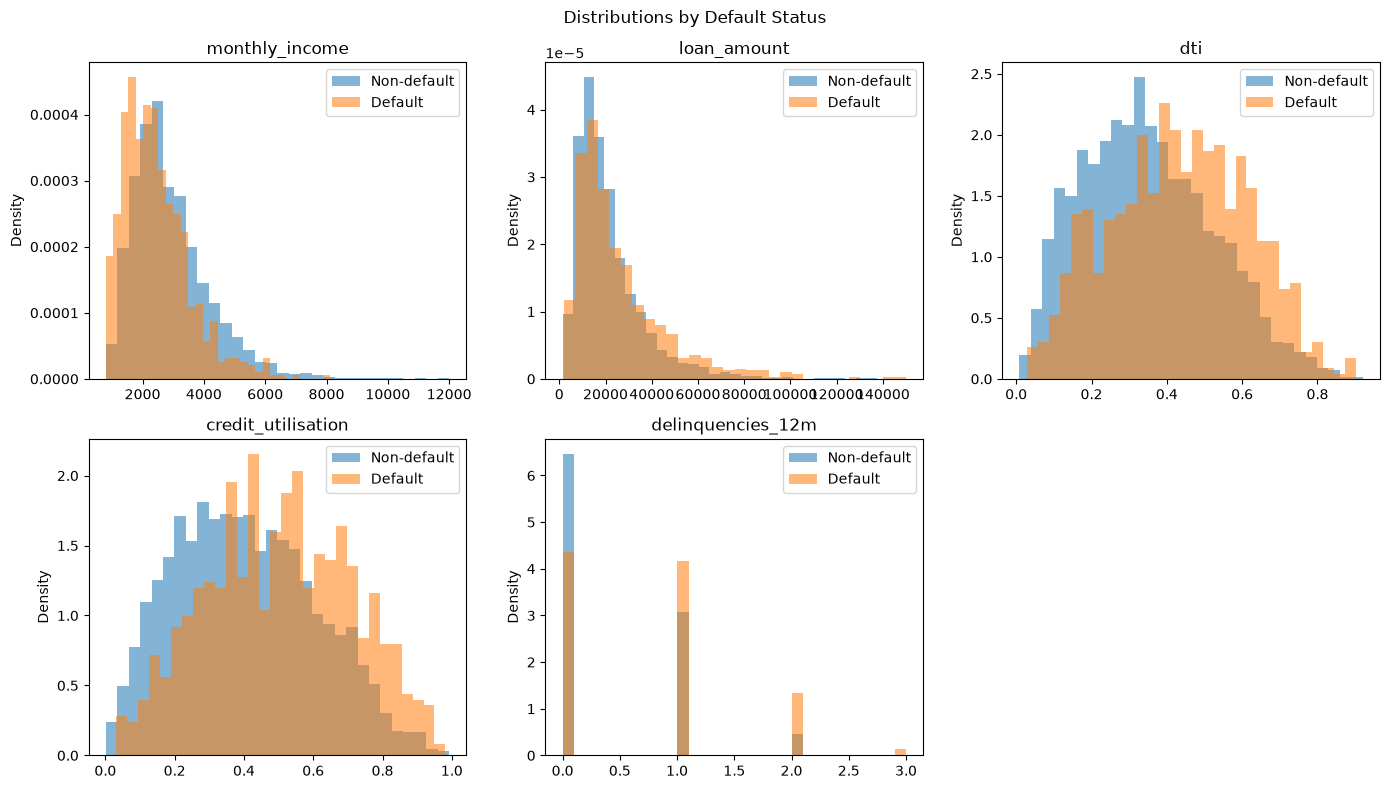

In [39]:
plot_vars = ['monthly_income', 'loan_amount', 'dti', 'credit_utilisation', 'delinquencies_12m']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, var in zip(axes, plot_vars):
    ax.hist(non_defaulted[var], bins=30, alpha=0.55, density=True, label='Non-default')
    ax.hist(defaulted[var], bins=30, alpha=0.55, density=True, label='Default')
    ax.set_title(var)
    ax.set_ylabel('Density')
    ax.legend()

for ax in axes[len(plot_vars):]:
    ax.set_visible(False)

plt.suptitle('Distributions by Default Status')
plt.tight_layout()
plt.show()

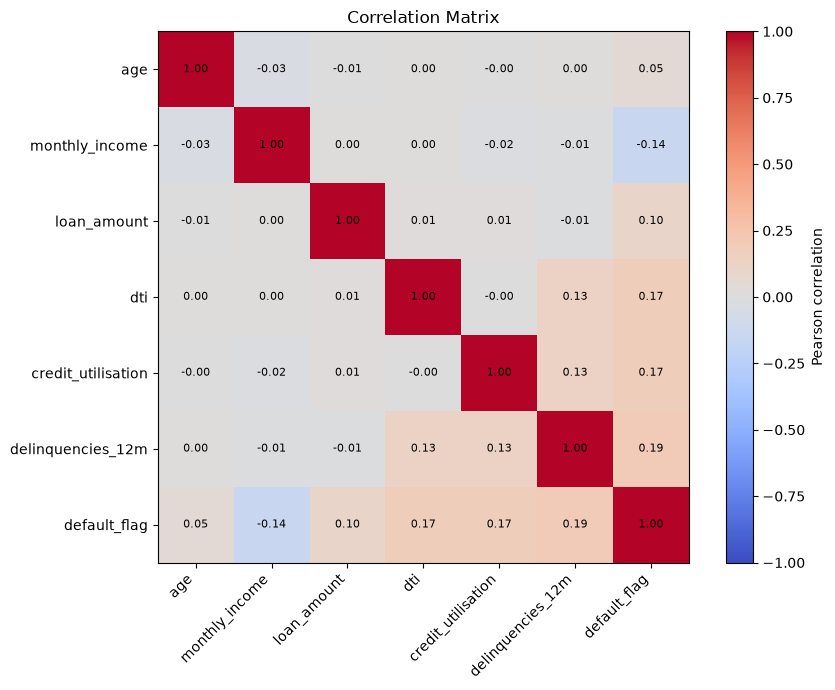

In [40]:
corr = data[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)

plt.colorbar(im, ax=ax, label='Pearson correlation')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 4. Statistical Modelling Theory

### 4.1 Logistic Regression

Logistic regression is a widely used method for modelling binary outcomes such as credit default. Instead of modelling the probability of default directly, it models the log-odds of default:

$$
\log\left(\frac{p_i}{1-p_i}\right)
=
\beta_0+\beta_1x_{1i}+\cdots+\beta_kx_{ki}
=
X_i\boldsymbol\beta
$$

The corresponding probability can be obtained using the sigmoid function:

$$
p_i=\sigma(X_i\boldsymbol\beta),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}}
$$

One advantage of logistic regression is that the estimated coefficients can be converted into odds ratios, making the results easier to interpret. For a one-unit increase in variable $x_j$, the odds ratio is:

$$
OR_j=e^{\beta_j}
$$

### 4.2 Probit Regression

Probit regression is another method for modelling binary outcomes. It is very similar to logistic regression, but it uses the cumulative standard normal distribution instead of the logistic function:

$$
P(Y_i=1 \mid X_i)=\Phi(X_i\boldsymbol\beta)
$$

In many practical applications, logistic and probit regression produce very similar predictions. The main difference lies in the mathematical function used to transform the linear predictor into a probability. For this reason, probit regression is included in the analysis to examine whether the choice of link function affects the results.

A commonly used approximation is:

$$
\beta_{logit}\approx1.6\,\beta_{probit}
$$

This relationship will be examined later when comparing the estimated models.

### 4.3 Decision Tree

A decision tree classifies observations by applying a sequence of simple decision rules. At each step, the algorithm selects the variable and threshold that best separate the observations into different classes.

To choose the best split, scikit-learn uses **Gini impurity** by default:

$$
G=1-\sum_k p_k^2
$$

where $p_k$ represents the proportion of observations belonging to class $k$ within a node.

A lower Gini value indicates that the observations in a node are more homogeneous. A node containing only one class has $G=0$, while a perfectly balanced 50/50 split has $G=0.5$.

The estimated probability of default is calculated as the proportion of defaulted borrowers within the final leaf node. As a result, a decision tree produces a limited number of distinct probability values, depending on the number of terminal leaves.

### 4.4 Validation Measures

Several metrics are used to evaluate model performance.

**ROC AUC** measures the model's ability to distinguish between defaulted and non-defaulted borrowers. A higher value indicates better discrimination.

The accuracy of predicted probabilities is evaluated using the **Brier Score** and **Log Loss**:

$$
Brier=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2
$$

$$
LogLoss=
-\frac{1}{n}
\sum_{i=1}^{n}
\left[
y_i\log(p_i)
+
(1-y_i)\log(1-p_i)
\right]
$$

Borrowers are classified as defaulted when their predicted probability exceeds a chosen threshold $t$:

$$
p_i \ge t
$$

Based on the resulting confusion matrix, the following metrics are calculated:

$$
Precision=\frac{TP}{TP+FP},
\qquad
Recall=\frac{TP}{TP+FN},
\qquad
F_1=
\frac{2\cdot Precision\cdot Recall}
{Precision+Recall}
$$

These measures provide different perspectives on model performance and help assess not only predictive accuracy but also the balance between correctly identifying defaults and avoiding false alarms.

### 4.5 Maximum Likelihood Estimation

The coefficients of logistic and probit regression are estimated using maximum likelihood. For borrower $i$, the probability of the observed binary outcome is:

$$P(Y_i=y_i)=p_i^{y_i}(1-p_i)^{1-y_i}$$

For $n$ independent observations, the likelihood and log-likelihood are:

$$L(\boldsymbol{\beta})=\prod_{i=1}^{n}p_i^{y_i}(1-p_i)^{1-y_i},\qquad
\ell(\boldsymbol{\beta})=\sum_{i=1}^{n}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]$$

The maximum-likelihood estimator is

$$\hat{\boldsymbol{\beta}}=\underset{\boldsymbol{\beta}}{\arg\max}\;\ell(\boldsymbol{\beta})$$

Maximising the log-likelihood is equivalent to minimising the average negative log-likelihood, which is exactly the log loss defined above.

### 4.6 Gradient, Hessian and the Newton-Raphson Method

For logistic regression $p_i=\sigma(X_i\boldsymbol\beta)$. The sigmoid has the convenient derivative

$$\sigma'(z)=\sigma(z)\big(1-\sigma(z)\big)$$

Applying the chain rule to one term of the log-likelihood:

$$\frac{\partial\ell_i}{\partial\boldsymbol\beta}
=\left(\frac{y_i}{p_i}-\frac{1-y_i}{1-p_i}\right)p_i(1-p_i)X_i^\top
=(y_i-p_i)X_i^\top$$

Summing over all observations gives the **gradient** in matrix form:

$$\nabla\ell(\boldsymbol\beta)=X^\top(\mathbf y-\mathbf p)$$

Differentiating once more gives the **Hessian**:

$$H(\boldsymbol\beta)=\frac{\partial^2\ell}{\partial\boldsymbol\beta\,\partial\boldsymbol\beta^\top}=-X^\top WX,\qquad W=\operatorname{diag}\big(p_i(1-p_i)\big)$$

Because all diagonal elements of $W$ are positive, $H$ is negative semi-definite, so $\ell(\boldsymbol\beta)$ is **concave**. When $X$ has full column rank, the maximum is therefore unique.

Setting $\nabla\ell=0$ has no closed-form solution, because $\mathbf p$ depends nonlinearly on $\boldsymbol\beta$. The **Newton-Raphson method** approximates $\ell$ with a second-order Taylor expansion around the current estimate and jumps to the maximum of that quadratic approximation:

$$\boldsymbol\beta^{(t+1)}=\boldsymbol\beta^{(t)}-H\big(\boldsymbol\beta^{(t)}\big)^{-1}\nabla\ell\big(\boldsymbol\beta^{(t)}\big)$$

Near the optimum the method converges quadratically, so only a few iterations are needed. The algorithm is implemented from scratch in Section 5.1 and compared with scikit-learn.

Convergence means that the optimisation reached a stable numerical solution. It does not prove that the model is correctly specified, but failure to converge would make the coefficient estimates unreliable.

## 5. Model Development

To evaluate the models fairly, the dataset was divided into a training sample (70%) and a test sample (30%). Stratified sampling was used so that both samples contained a similar proportion of defaulted borrowers. The models were estimated using the training data, while all performance comparisons were based on the separate test sample.

In [41]:
X = data[FEATURES].copy()
y = data[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED
)

# True PDs for the test borrowers (used only for evaluation in Section 6.2)
true_pd_test = data.loc[X_test.index, 'true_pd'].to_numpy()

print('Training observations:', len(X_train), f'| default rate {y_train.mean():.2%}')
print('Test observations:', len(X_test), f'| default rate {y_test.mean():.2%}')

Training observations: 3500 | default rate 15.83%
Test observations: 1500 | default rate 15.80%


In [42]:
def make_logit() -> Pipeline:
    # Standardised logistic regression.
    # C=1e6 makes the L2 penalty negligible, so the model is effectively
    # an unpenalised maximum-likelihood fit that is comparable with probit.
    return Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(C=1e6, max_iter=2000, random_state=RANDOM_SEED)),
    ])


baseline_logit = make_logit().fit(X_train[['dti']], y_train)
full_logit = make_logit().fit(X_train, y_train)

# Probit is estimated with statsmodels on the same standardised predictors
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
probit = sm.Probit(y_train, sm.add_constant(X_train_s)).fit(disp=False)

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=80, random_state=RANDOM_SEED)
tree.fit(X_train, y_train)

print('Models fitted successfully.')

Models fitted successfully.


In [43]:
# Check the Probit maximum-likelihood optimisation result
print('Probit model converged:', probit.mle_retvals['converged'])
print('Iterations:', probit.mle_retvals['iterations'])
print('Log-likelihood:', round(probit.llf, 4))

Probit model converged: True
Iterations: 6
Log-likelihood: -1325.0257


### 5.1 Logistic Regression from Scratch (Newton-Raphson)

The function below implements the Newton-Raphson estimation procedure described in Section 4.6 using NumPy. A column of ones is added to account for the intercept term. At each iteration, the coefficient update is obtained by solving
$$
H\,\Delta=\nabla\ell
$$
using `np.linalg.solve`, which is generally more numerically stable and computationally efficient than explicitly calculating \(H^{-1}\). The algorithm stops when the maximum absolute change in the estimated coefficients falls below the specified tolerance level.

In [44]:
def logit_newton_raphson(X: np.ndarray, y: np.ndarray,
                         tol: float = 1e-10, max_iter: int = 50):
    # Fit an unpenalised logistic regression with the Newton-Raphson method.
    #
    # Returns the coefficient vector (intercept first) and the history of
    # log-likelihood values, one per iteration.
    X = np.column_stack([np.ones(len(X)), X])
    y = np.asarray(y, dtype=float)
    beta = np.zeros(X.shape[1])
    history = []

    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-X @ beta))
        log_likelihood = np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
        history.append(log_likelihood)

        gradient = X.T @ (y - p)                     # X^T (y - p)
        hessian = -(X.T * (p * (1 - p))) @ X         # -X^T W X
        step = np.linalg.solve(hessian, gradient)    # H^{-1} * gradient
        beta = beta - step

        if np.max(np.abs(step)) < tol:
            break

    return beta, history


beta_nr, ll_history = logit_newton_raphson(X_train_s.to_numpy(), y_train.to_numpy())

sklearn_beta = np.concatenate([full_logit.named_steps['model'].intercept_,
                               full_logit.named_steps['model'].coef_[0]])

comparison = pd.DataFrame({
    'Newton-Raphson': beta_nr,
    'scikit-learn': sklearn_beta,
}, index=['intercept'] + FEATURES)
comparison['Absolute difference'] = (comparison['Newton-Raphson'] - comparison['scikit-learn']).abs()

print(f'Iterations: {len(ll_history)}')
print(f'Maximum absolute difference: {comparison["Absolute difference"].max():.2e}')
comparison.round(6)

Iterations: 7
Maximum absolute difference: 7.64e-04


,Newton-Raphson,scikit-learn,Absolute difference
intercept,-2.000241,-1.999960,0.000280
age,0.130067,0.130500,0.000433
monthly_income,-0.541154,-0.540390,0.000764
loan_amount,0.270523,0.270383,0.000140
dti,0.422035,0.422416,0.000381
credit_utilisation,0.460080,0.460476,0.000396
delinquencies_12m,0.453182,0.452826,0.000356


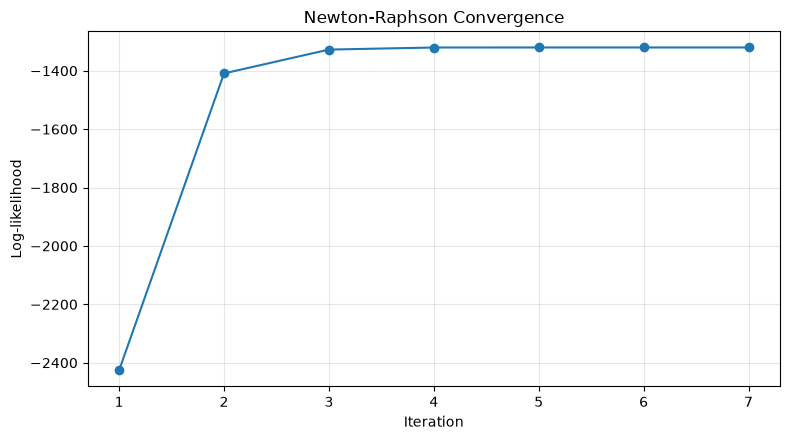

In [45]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(ll_history) + 1), ll_history, marker='o')
ax.set_xlabel('Iteration')
ax.set_ylabel('Log-likelihood')
ax.set_title('Newton-Raphson Convergence')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation.** The Newton-Raphson algorithm converged after 7 iterations. Most of the improvement in the log-likelihood occurred during the first few iterations, and the values became almost unchanged after about five steps. The estimated coefficients are nearly identical to those obtained with scikit-learn, with a maximum difference of only
$$
8\times10^{-4}.
$$
This small discrepancy is likely caused by the weak L2 regularisation used by scikit-learn (\(C=10^6\)) and minor differences in the stopping criteria. Overall, the results confirm that the manual implementation successfully reproduces the maximum-likelihood solution obtained by the standard software package.

### 5.2 Logistic Coefficients and Odds Ratios

The predictors were standardised before model estimation. Therefore, each coefficient corresponds to a one-standard-deviation increase in the respective variable. Standardisation makes it easier to compare the relative importance of variables that are measured in different units.

In [46]:
coef = full_logit.named_steps['model'].coef_[0]
coefficient_table = pd.DataFrame({
    'Variable': FEATURES,
    'Standardised coefficient': coef,
    'Odds ratio per 1 SD': np.exp(coef),
}).sort_values('Standardised coefficient', key=np.abs, ascending=False)
coefficient_table.round(4)

,Variable,Standardised coefficient,Odds ratio per 1 SD
1,monthly_income,-0.5404,0.5825
4,credit_utilisation,0.4605,1.5848
5,delinquencies_12m,0.4528,1.5728
3,dti,0.4224,1.5256
2,loan_amount,0.2704,1.3105
0,age,0.1305,1.1394


### 5.3 Multicollinearity Diagnostic

To assess potential multicollinearity, the Variance Inflation Factor (VIF) is calculated for each predictor:

$$
VIF_j=\frac{1}{1-R_j^2}
$$

where \(R_j^2\) is obtained by regressing predictor \(x_j\) on all remaining predictors. A constant term is included in each auxiliary regression.

VIF values close to 1 indicate little or no linear relationship between the predictors. Higher values suggest increasing levels of multicollinearity, with values above 5 often considered a warning sign and values above 10 generally indicating a more serious issue.

The VIF results help determine whether strong correlations between predictors could affect the stability and interpretation of the regression coefficients.

In [47]:
vif_input = sm.add_constant(X_train_s)
vif_table = pd.DataFrame({
    'Variable': FEATURES,
    'VIF': [variance_inflation_factor(vif_input.values, i)
            for i in range(1, vif_input.shape[1])],   # index 0 is the constant
})
vif_table.round(3)

,Variable,VIF
0,age,1.003
1,monthly_income,1.004
2,loan_amount,1.001
3,dti,1.017
4,credit_utilisation,1.021
5,delinquencies_12m,1.037


### 5.4 Logistic versus Probit Coefficients

Section 4.2 suggested that logistic coefficients are typically about 1.6 to 1.8 times larger than the corresponding probit coefficients. To assess whether this relationship holds in the current dataset, the coefficient ratio is calculated for each predictor using the same standardised data.

In [48]:
link_comparison = pd.DataFrame({
    'Logit coefficient': coef,
    'Probit coefficient': probit.params[FEATURES].to_numpy(),
}, index=FEATURES)
link_comparison['Ratio logit / probit'] = (link_comparison['Logit coefficient']
                                           / link_comparison['Probit coefficient'])
print(f"Mean ratio: {link_comparison['Ratio logit / probit'].mean():.3f}")
link_comparison.round(4)

Mean ratio: 1.853


,Logit coefficient,Probit coefficient,Ratio logit / probit
age,0.1305,0.0727,1.7938
monthly_income,-0.5404,-0.2715,1.9905
loan_amount,0.2704,0.1473,1.8361
dti,0.4224,0.2256,1.8724
credit_utilisation,0.4605,0.2505,1.8381
delinquencies_12m,0.4528,0.2535,1.7866


**Interpretation.** The ratio between the logistic and probit coefficients is quite consistent across all predictors, ranging from 1.79 to 1.99 with an average value of 1.85. This suggests that the two models produce very similar results and mainly differ in the scale of their coefficients.

The observed ratios are slightly higher than the commonly cited value of 1.6 discussed in Section 4.2. One possible explanation is that the default rate in this dataset is relatively low (around 16%), meaning that many observations fall away from the centre of the probability distribution. Under these conditions, the scaling relationship between the two models tends to move closer to

$$
\frac{\pi}{\sqrt{3}}\approx1.81.
$$

Overall, the findings indicate that logistic and probit regression capture essentially the same underlying relationships between borrower characteristics and default risk.

## 6. Model Validation and Comparison

This section evaluates how well the models perform on unseen data. The assessment covers discrimination, probability accuracy, classification performance, calibration, and potential overfitting. Since the dataset is synthetic, the predicted probabilities can also be compared with the true probabilities of default used during data generation.

In [49]:
def evaluate_model(y_tr, p_tr, y_te, p_te, threshold: float = THRESHOLD) -> dict:
    # Return discrimination, probability-accuracy and classification metrics.
    predicted_class = (p_te >= threshold).astype(int)
    auc_train = roc_auc_score(y_tr, p_tr)
    auc_test = roc_auc_score(y_te, p_te)
    return {
        'Train AUC': auc_train,
        'Test AUC': auc_test,
        'AUC gap': auc_train - auc_test,
        'Brier score': brier_score_loss(y_te, p_te),
        'Log loss': log_loss(y_te, p_te),
        'Accuracy': accuracy_score(y_te, predicted_class),
        'Precision': precision_score(y_te, predicted_class, zero_division=0),
        'Recall': recall_score(y_te, predicted_class, zero_division=0),
        'F1': f1_score(y_te, predicted_class, zero_division=0),
    }


models = {
    'Baseline Logit': {
        'train': baseline_logit.predict_proba(X_train[['dti']])[:, 1],
        'test': baseline_logit.predict_proba(X_test[['dti']])[:, 1],
    },
    'Full Logit': {
        'train': full_logit.predict_proba(X_train)[:, 1],
        'test': full_logit.predict_proba(X_test)[:, 1],
    },
    'Probit': {
        'train': np.asarray(probit.predict(sm.add_constant(X_train_s))),
        'test': np.asarray(probit.predict(sm.add_constant(X_test_s))),
    },
    'Decision Tree': {
        'train': tree.predict_proba(X_train)[:, 1],
        'test': tree.predict_proba(X_test)[:, 1],
    },
}

results = pd.DataFrame({
    name: evaluate_model(y_train, p['train'], y_test, p['test'])
    for name, p in models.items()
}).T.rename_axis('Model').sort_values('Test AUC', ascending=False)
results.round(4)

,Train AUC,Test AUC,AUC gap,Brier score,Log loss,Accuracy,Precision,Recall,F1
Model,,,,,,,,,
Full Logit,0.7545,0.7495,0.0050,0.1169,0.3801,0.8247,0.4278,0.3249,0.3693
Probit,0.7543,0.7489,0.0054,0.1170,0.3802,0.8247,0.4270,0.3207,0.3663
Baseline Logit,0.6204,0.6666,-0.0462,0.1278,0.4163,0.8293,0.2286,0.0338,0.0588
Decision Tree,0.6989,0.6625,0.0364,0.1269,0.4128,0.8000,0.3368,0.2743,0.3023


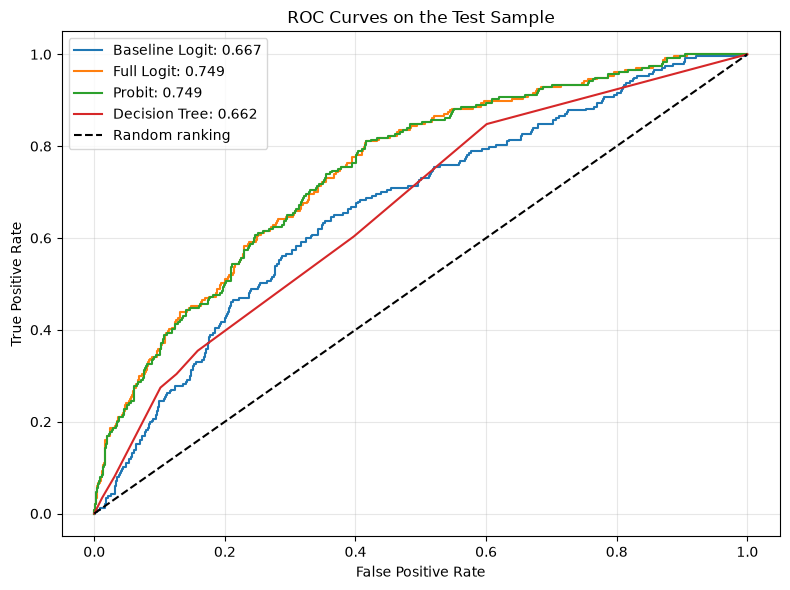

In [50]:
plt.figure(figsize=(8, 6))
for name, p in models.items():
    fpr, tpr, _ = roc_curve(y_test, p['test'])
    plt.plot(fpr, tpr, label=f"{name}: {roc_auc_score(y_test, p['test']):.3f}")

plt.plot([0, 1], [0, 1], 'k--', label='Random ranking')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves on the Test Sample')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

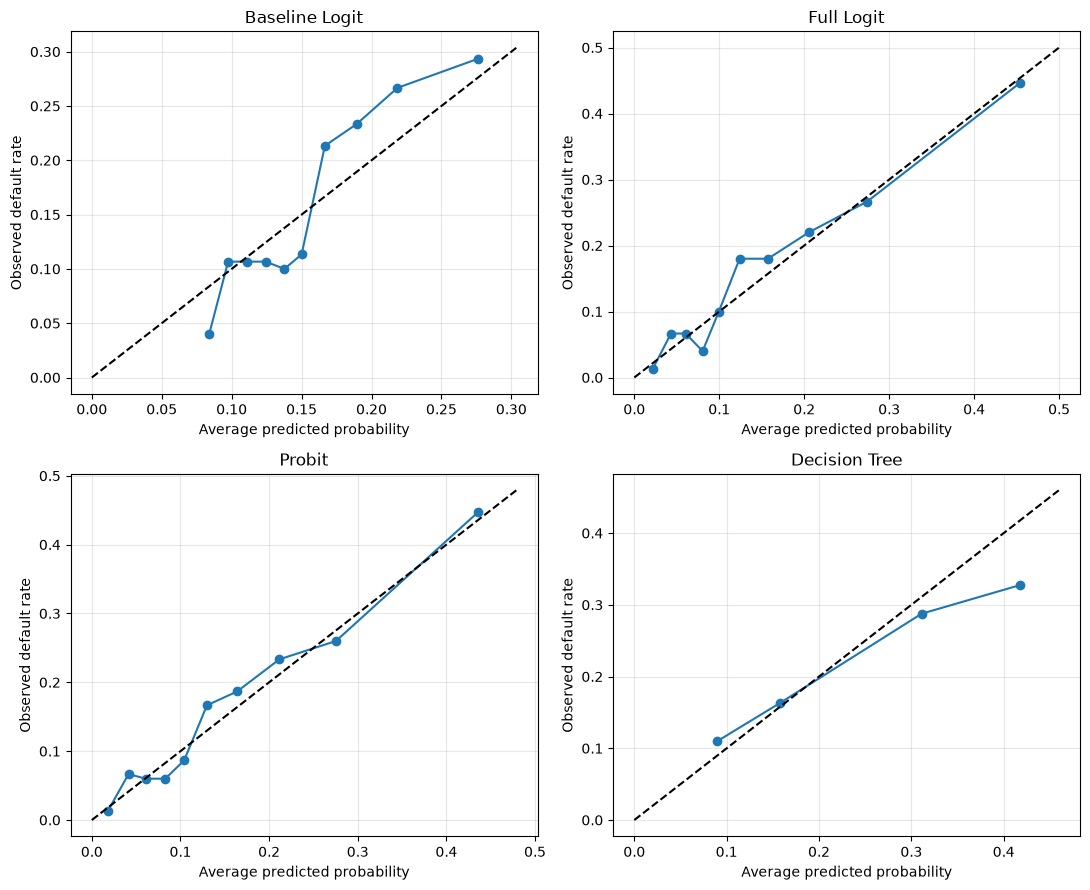

In [51]:
def calibration_table(probabilities, observed, groups: int = 10) -> pd.DataFrame:
    # Compare average predicted and observed default rates in risk groups.
    frame = pd.DataFrame({'predicted': probabilities, 'observed': np.asarray(observed)})
    frame['group'] = pd.qcut(frame['predicted'], q=groups, duplicates='drop')
    return frame.groupby('group', observed=False).agg(
        borrowers=('observed', 'size'),
        average_predicted=('predicted', 'mean'),
        observed_rate=('observed', 'mean'),
    ).reset_index(drop=True)


calibration_tables = {name: calibration_table(p['test'], y_test) for name, p in models.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, table) in zip(axes.flatten(), calibration_tables.items()):
    upper = table['average_predicted'].max() * 1.1
    ax.plot(table['average_predicted'], table['observed_rate'], 'o-', label=name)
    ax.plot([0, upper], [0, upper], 'k--')
    ax.set_title(name)
    ax.set_xlabel('Average predicted probability')
    ax.set_ylabel('Observed default rate')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

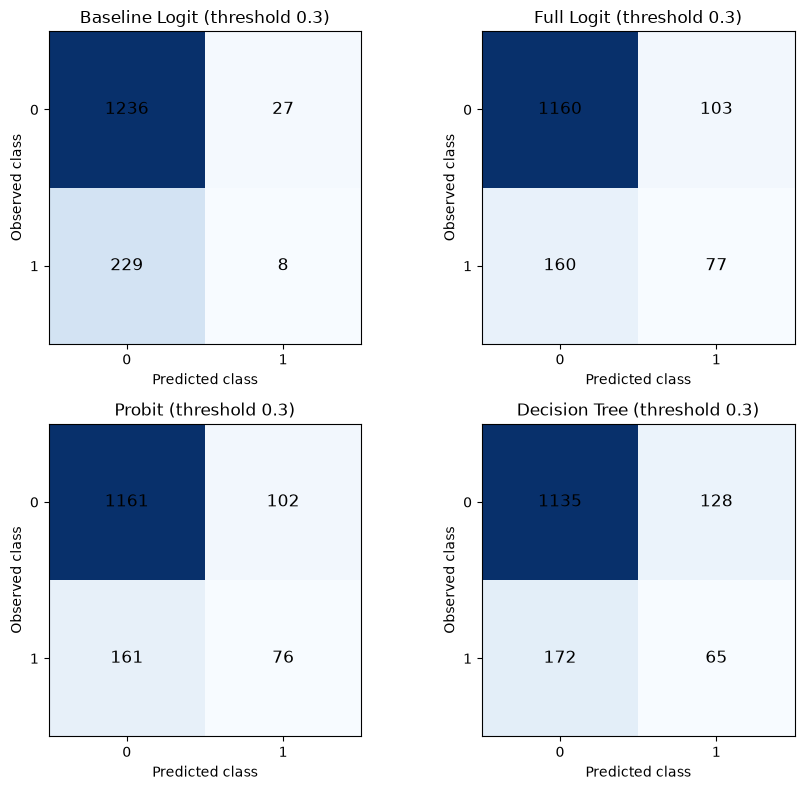

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (name, p) in zip(axes.flatten(), models.items()):
    cm = confusion_matrix(y_test, (p['test'] >= THRESHOLD).astype(int))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=12)
    ax.set_title(f'{name} (threshold {THRESHOLD})')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Observed class')

plt.tight_layout()
plt.show()

In [53]:
thresholds = [0.20, 0.30, 0.40, 0.50]
p_full = models['Full Logit']['test']

threshold_rows = []
for t in thresholds:
    predicted_class = (p_full >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted_class).ravel()
    threshold_rows.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, predicted_class),
        'Precision': precision_score(y_test, predicted_class, zero_division=0),
        'Recall': recall_score(y_test, predicted_class, zero_division=0),
        'Specificity': tn / (tn + fp),
        'F1': f1_score(y_test, predicted_class, zero_division=0),
    })

pd.DataFrame(threshold_rows).round(4)

,Threshold,Accuracy,Precision,Recall,Specificity,F1
0,0.2,0.7460,0.3154,0.5190,0.7886,0.3923
1,0.3,0.8247,0.4278,0.3249,0.9184,0.3693
2,0.4,0.8440,0.5161,0.2025,0.9644,0.2909
3,0.5,0.8460,0.5682,0.1055,0.9850,0.1779


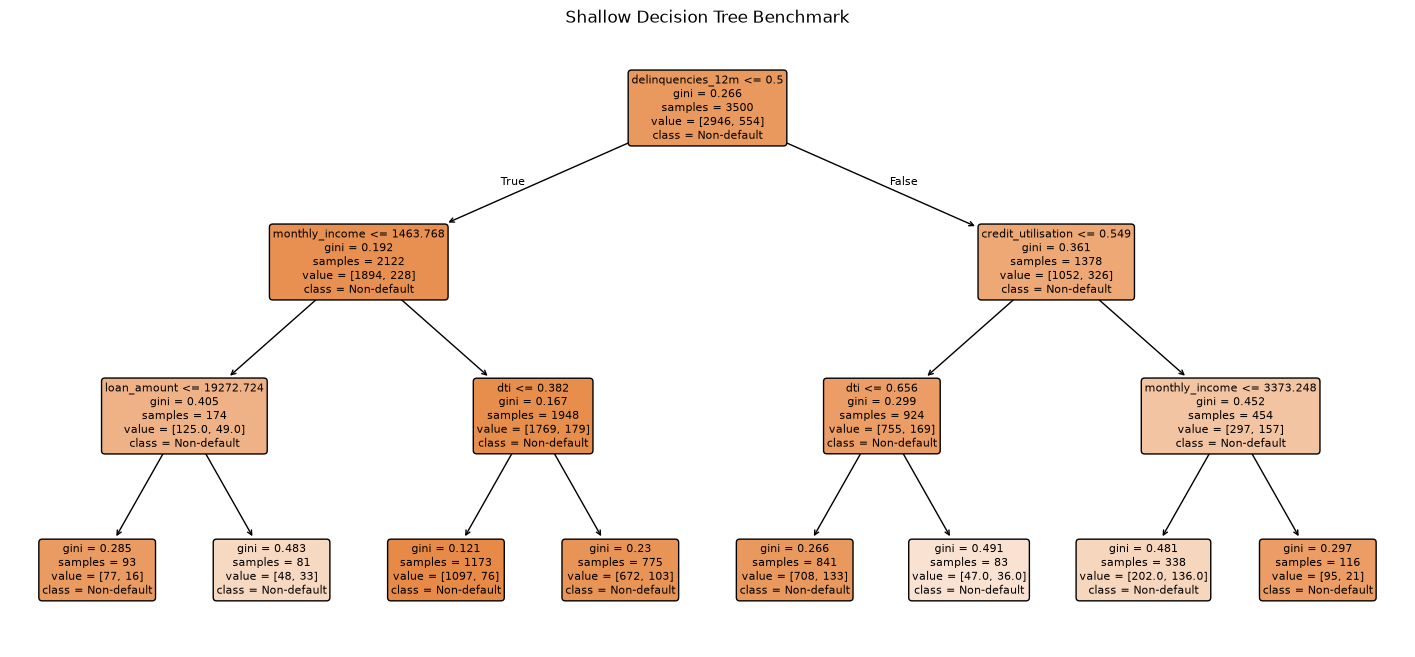

In [54]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=FEATURES, class_names=['Non-default', 'Default'],
          filled=True, rounded=True, fontsize=8)
plt.title('Shallow Decision Tree Benchmark')
plt.show()

### 6.1 Cross-Validation Sensitivity Analysis

The main model comparison is based on a single stratified training and test split. Although the test sample provides an unbiased evaluation, the measured performance may still be influenced by the particular way the data are divided.

To examine the stability of the results, five-fold stratified cross-validation is performed as an additional sensitivity analysis. The dataset is divided into five approximately equal parts. In each iteration, four folds are used to train the model and the remaining fold is used for validation. This process is repeated until every fold has served once as the validation set. Stratification ensures that the proportion of defaults remains similar across all folds.

For \(K=5\) folds, the average validation AUC and its standard deviation are calculated as:

$$
\overline{AUC}_{CV}=\frac{1}{K}\sum_{k=1}^{K}AUC_k,
\qquad
s_{AUC}=
\sqrt{
\frac{1}{K-1}
\sum_{k=1}^{K}
\left(
AUC_k-\overline{AUC}_{CV}
\right)^2
}
$$

The mean AUC provides an overall measure of predictive performance, while the standard deviation shows how much the results vary across different sample partitions. A smaller standard deviation indicates that the model performs consistently across folds.

The analysis includes the models implemented through the scikit-learn interface. Probit regression remains part of the main test-sample comparison but is not included in the cross-validation analysis because it is estimated using statsmodels. Cross-validation is used as a complement to, rather than a replacement for, the independent test sample evaluation.

In [55]:
cross_validation = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
cv_models = {
    'Baseline Logit': (baseline_logit, ['dti']),
    'Full Logit': (full_logit, FEATURES),
    'Decision Tree': (tree, FEATURES),
}
scoring = {'auc': 'roc_auc', 'neg_brier': 'neg_brier_score', 'neg_log_loss': 'neg_log_loss'}

cv_results = []
fold_auc_results = pd.DataFrame(index=[f'Fold {k}' for k in range(1, N_FOLDS + 1)])

for model_name, (model, model_features) in cv_models.items():
    scores = cross_validate(model, X[model_features], y, cv=cross_validation,
                            scoring=scoring, return_train_score=True)
    cv_results.append({
        'Model': model_name,
        'Mean Train AUC': scores['train_auc'].mean(),
        'Mean Validation AUC': scores['test_auc'].mean(),
        'Validation AUC SD': scores['test_auc'].std(ddof=1),
        'Mean Validation Brier': -scores['test_neg_brier'].mean(),
        'Mean Validation Log Loss': -scores['test_neg_log_loss'].mean(),
        'Mean AUC Gap': scores['train_auc'].mean() - scores['test_auc'].mean(),
    })
    fold_auc_results[model_name] = scores['test_auc']

cross_validation_summary = (pd.DataFrame(cv_results)
                            .set_index('Model')
                            .sort_values('Mean Validation AUC', ascending=False))
cross_validation_summary.round(4)

,Mean Train AUC,Mean Validation AUC,Validation AUC SD,Mean Validation Brier,Mean Validation Log Loss,Mean AUC Gap
Model,,,,,,
Full Logit,0.7537,0.7505,0.0267,0.1156,0.3793,0.0032
Decision Tree,0.6989,0.6410,0.0245,0.1280,0.4201,0.0580
Baseline Logit,0.6341,0.6341,0.0337,0.1292,0.4223,-0.0000


In [56]:
fold_auc_results.round(4)

,Baseline Logit,Full Logit,Decision Tree
Fold 1,0.5800,0.7365,0.6029
Fold 2,0.6250,0.7299,0.6348
Fold 3,0.6541,0.7961,0.6671
Fold 4,0.6657,0.7521,0.6559
Fold 5,0.6458,0.7377,0.6443


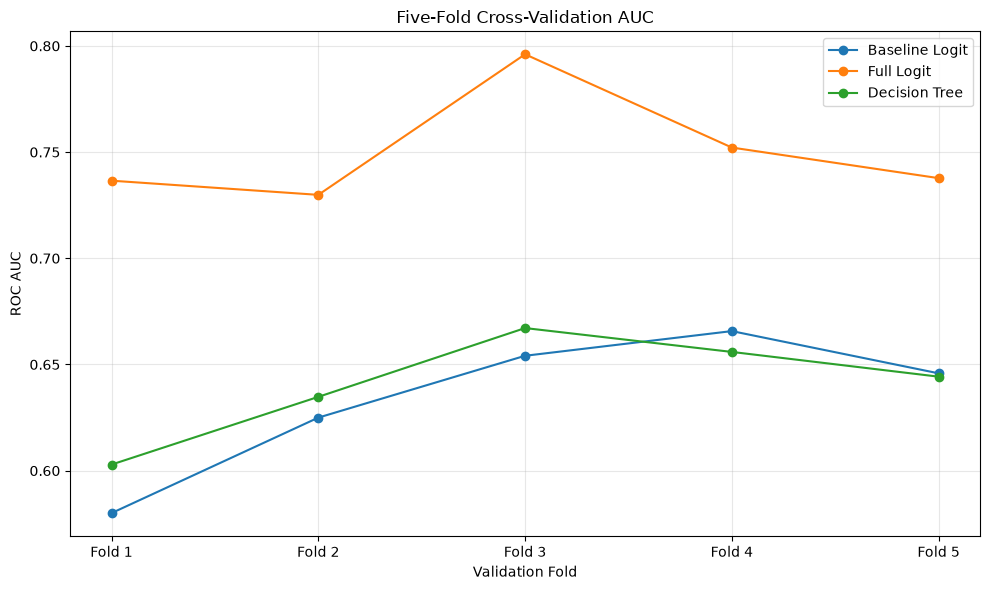

In [57]:
plt.figure(figsize=(10, 6))
for model_name in fold_auc_results.columns:
    plt.plot(fold_auc_results.index, fold_auc_results[model_name], marker='o', label=model_name)

plt.title('Five-Fold Cross-Validation AUC')
plt.xlabel('Validation Fold')
plt.ylabel('ROC AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation.** The cross-validation results are consistent with the findings from the test sample. The full logistic regression achieves the highest average validation AUC (0.7505) and performs best in all five folds. The difference between its training and validation performance is very small (0.0032), suggesting that the model generalises well to unseen data. The decision tree achieves a lower average validation AUC (0.6410) than the full logistic regression. In addition, the gap between training and validation performance is noticeably larger (0.058), suggesting a moderate degree of overfitting, even though the tree depth was restricted. For the baseline logistic model, the negative train-test gap observed in the single train-test split (-0.0462) is no longer present under cross-validation. The training and validation results are almost identical, indicating that the earlier result was likely caused by a particularly favourable test sample rather than superior out-of-sample performance. Overall, the cross-validation analysis confirms the ranking observed in the test-sample evaluation: the full logistic regression provides the strongest and most stable predictive performance, while the decision tree shows weaker generalisation despite its ability to capture nonlinear patterns.

### 6.2 Comparison with the True Probability of Default

In real-world credit risk modelling, the true probability of default is unknown and model performance can only be evaluated against the observed default outcomes. In this project, however, the dataset is synthetic, which means that the true probability of default is available for every borrower. This allows an additional assessment of how closely the model predictions match the underlying data-generating process.

Two measures are considered:

1. **Oracle AUC**: the AUC obtained when borrowers are ranked using their true probabilities of default. Because defaults are generated as random outcomes, even a perfect model cannot achieve an AUC of 1. Therefore, the Oracle AUC can be viewed as the highest discrimination that can be achieved on this particular test sample.

2. **Distance to the true probability of default**: the difference between each model's predicted probability and the known true probability of default. This is measured using the Mean Absolute Error (MAE) and the Root Mean Squared Error (RMSE):

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|\hat p_i-p_i|,
\qquad
RMSE=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
(\hat p_i-p_i)^2
}
$$

Smaller values of MAE and RMSE indicate that the predicted probabilities are closer to the true probabilities used to generate the synthetic data.

In [58]:
oracle_auc = roc_auc_score(y_test, true_pd_test)
print(f'Oracle AUC (ranking by true PD): {oracle_auc:.4f}')

truth_rows = []
for name, p in models.items():
    errors = p['test'] - true_pd_test
    test_auc = roc_auc_score(y_test, p['test'])
    truth_rows.append({
        'Model': name,
        'Test AUC': test_auc,
        'Share of oracle AUC': test_auc / oracle_auc,
        'MAE vs true PD': np.mean(np.abs(errors)),
        'RMSE vs true PD': np.sqrt(np.mean(errors ** 2)),
        'Correlation with true PD': np.corrcoef(p['test'], true_pd_test)[0, 1],
    })

truth_comparison = (pd.DataFrame(truth_rows)
                    .set_index('Model')
                    .sort_values('RMSE vs true PD'))
truth_comparison.round(4)

Oracle AUC (ranking by true PD): 0.7599


,Test AUC,Share of oracle AUC,MAE vs true PD,RMSE vs true PD,Correlation with true PD
Model,,,,,
Full Logit,0.7495,0.9863,0.0247,0.0532,0.9337
Probit,0.7489,0.9855,0.0274,0.0566,0.9259
Decision Tree,0.6625,0.8718,0.0776,0.1240,0.5586
Baseline Logit,0.6666,0.8773,0.0887,0.1310,0.4527


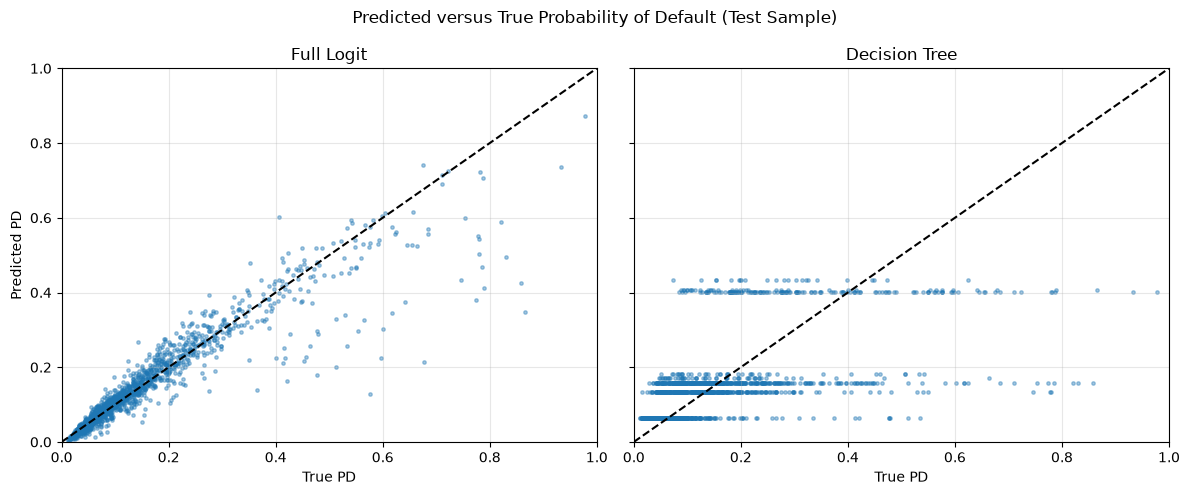

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, ['Full Logit', 'Decision Tree']):
    ax.scatter(true_pd_test, models[name]['test'], s=6, alpha=0.4)
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(name)
    ax.set_xlabel('True PD')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Predicted PD')
plt.suptitle('Predicted versus True Probability of Default (Test Sample)')
plt.tight_layout()
plt.show()

**Interpretation.** The availability of the true probability of default makes it possible to evaluate the models against the best achievable benchmark. Even if a model had access to the true PD values, it would achieve a test AUC of only 0.7599 because defaults are generated as random outcomes rather than being perfectly deterministic.

The full logistic regression performs very close to this benchmark, achieving 98.6% of the oracle AUC. It also produces probability estimates that are highly consistent with the true PD values, with an average error of approximately 2.5 percentage points and a correlation of 0.93. These results are particularly encouraging because the model does not include all features of the data-generating process, such as the interaction between DTI and credit utilisation or the nonlinear loan-burden effect.

The probit model delivers nearly identical results, which is consistent with the strong similarity already observed between the two approaches.

The decision tree performs less well, reaching about 87% of the oracle AUC and a correlation of 0.56 with the true probabilities. Although decision trees can capture nonlinear relationships, the limited tree depth used in this analysis results in a relatively small number of predicted probability values. This reduces the model's ability to closely approximate the underlying default probabilities.

The scatter plots illustrate these differences clearly. The predictions from the logistic and probit models are concentrated near the diagonal line, indicating close agreement with the true probabilities. In contrast, the decision tree produces a series of horizontal bands, reflecting its piecewise-constant probability estimates.

## 7. Results and Discussion

| Model | Test AUC | CV AUC (SD) | Brier | Log loss | Recall @0.30 | Share of oracle AUC |
|---|---|---|---|---|---|---|
| Full Logit | **0.7495** | **0.7505 (0.027)** | **0.1169** | **0.3801** | **0.325** | **98.6%** |
| Probit | 0.7489 | – | 0.1170 | 0.3802 | 0.321 | 98.6% |
| Baseline Logit | 0.6666 | 0.6341 (0.034) | 0.1278 | 0.4163 | 0.034 | 87.7% |
| Decision Tree | 0.6625 | 0.6410 (0.025) | 0.1269 | 0.4128 | 0.274 | 87.2% |

**Discrimination.** The full logistic regression clearly outperforms the baseline model. Adding information such as DTI, credit utilisation, and delinquency history increases the test AUC from 0.667 to 0.750. The cross-validation results show a very similar improvement, which suggests that the gain is consistent across different samples and not driven by a particular train-test split.

**Calibration.** The full logit and probit models achieve the lowest Brier scores and log-loss values, indicating more accurate probability estimates. Their calibration curves also remain close to the ideal diagonal line. The decision tree shows weaker calibration because borrowers within the same terminal leaf receive the same predicted probability.

**Classification Performance.** Accuracy alone is not a reliable metric in this dataset because the majority of borrowers do not default. Although the baseline logistic model achieves the highest overall accuracy, it identifies very few actual defaults. At a threshold of 0.30, the full logistic model correctly identifies 77 of the 237 defaults in the test sample, achieving a recall of 0.325 and a precision of 0.428. Lowering the threshold to 0.20 increases recall to 0.519 but reduces precision to 0.315. This illustrates the trade-off between identifying more risky borrowers and generating more false positives.

**Logit vs. Probit.** The logistic and probit models produce nearly identical results across all evaluation metrics. Their coefficient estimates differ mainly by a relatively constant scaling factor, while their predictions remain almost the same. In practice, the choice between the two models has little impact on predictive performance. Logistic regression may be preferred because its coefficients can be interpreted directly through odds ratios.

**Interpretability.** The estimated coefficients indicate that higher income is associated with a lower probability of default, while higher DTI, credit utilisation, and delinquency counts are associated with increased default risk. The VIF values remain very close to 1, suggesting that multicollinearity is not a concern and that the coefficient estimates are stable.

**Comparison with the True Probabilities.** The full logistic regression performs remarkably close to the best achievable result on this dataset, reaching 98.6% of the oracle AUC. Despite its relatively simple structure and the omission of some nonlinear effects included in the data-generating process, it provides highly accurate probability estimates. The decision tree is more flexible but does not achieve the same level of performance, mainly because its predictions are less precise and more variable.

## 8. Limitations

This project has several limitations that should be considered when interpreting the results.

1. The dataset is fully synthetic and was generated using predefined assumptions. As a result, the findings cannot be directly generalised to real borrowers or real credit portfolios.
2. The logistic and probit models do not include all relationships that were used when generating the data. In particular, interaction effects and nonlinear terms are omitted, which limits how closely these models can reproduce the true probabilities of default.
3. The analysis is based on a relatively small set of borrower characteristics and does not include additional information that is often used in practice, such as macroeconomic indicators, behavioural data, repayment history, or product-specific characteristics.
4. Although cross-validation provides a more robust assessment of model stability, the synthetic cross-sectional dataset does not allow for temporal validation or external validation on an independent population.
5. Model calibration is evaluated using graphical comparisons across risk groups. More formal calibration tests and confidence intervals are not included.
6. The classification thresholds examined in the project are chosen for illustration purposes. In practice, threshold selection would also depend on business objectives and the relative costs of false positives and false negatives.
7. The project does not address several important practical challenges encountered in real credit risk modelling, including reject inference, sample selection bias, missing values, and changes in borrower behaviour over time.

## 9. Conclusion

This project examined the relationship between borrower characteristics and credit default using a synthetic dataset. The analysis covered the full modelling process, including data generation, exploratory analysis, model development, validation, and comparison of alternative modelling approaches.

The main findings can be summarised as follows:
1. Delinquencies, credit utilisation, debt-to-income ratio, and income showed the strongest differences between defaulted and non-defaulted borrowers.
2. The multivariable logistic regression performed substantially better than the baseline model that relied only on DTI.
3. Logistic and probit regression produced almost identical predictions, with differences mainly limited to the scale of their coefficients.
4. The decision tree was able to capture nonlinear patterns, but it did not outperform the regression models in terms of predictive performance or stability.
5. Overall, the full logistic regression provided the best balance between predictive accuracy, calibration, model stability, and interpretability.

The study also demonstrated the importance of using multiple evaluation measures rather than relying on accuracy alone. Metrics such as ROC AUC, Brier score, log loss, calibration, and cross-validation provided a more complete view of model performance. Because the dataset was synthetic, it was possible to compare the predicted probabilities with the true probabilities of default used during data generation. This additional analysis showed that the full logistic regression performed very close to the best achievable benchmark on the available data. Future work could include adding interaction and nonlinear terms to the regression models, applying formal calibration tests, performing repeated cross-validation with confidence intervals, and evaluating the same framework on a real credit risk dataset.

Although the findings apply only to the synthetic sample, the project demonstrates a complete workflow for developing, validating, and interpreting credit risk models and illustrates the practical application of statistical modelling techniques.

## 10. References

### Course Materials

1. SoftUni. *Statistics*. Course lecture materials, Math Concepts for Developers.
2. SoftUni. *Linear Algebra*. Course lecture materials, Math Concepts for Developers.
3. SoftUni. *Calculus*. Course lecture materials, Math Concepts for Developers.
4. SoftUni. *Final Exam: Project Guidelines*. Math Concepts for Developers.

### Literature

5. Amemiya, T. (1981). Qualitative Response Models: A Survey. *Journal of Economic Literature*, 19(4), 1483-1536.
6. Hosmer, D. W., Lemeshow, S. and Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley.
7. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum Associates.

### Official Documentation

8. scikit-learn developers. *LogisticRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
9. scikit-learn developers. *DecisionTreeClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
10. scikit-learn developers. *cross_validate*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
11. scikit-learn developers. *Model evaluation*. https://scikit-learn.org/stable/modules/model_evaluation.html
12. statsmodels developers. *Probit*. https://www.statsmodels.org/dev/generated/statsmodels.discrete.discrete_model.Probit.html
13. statsmodels developers. *Variance Inflation Factor*. https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html
14. SciPy developers. *scipy.stats.mannwhitneyu*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html
15. NumPy developers. *NumPy documentation*. https://numpy.org/doc/stable/
16. pandas developers. *pandas documentation*. https://pandas.pydata.org/docs/
17. Matplotlib developers. *Matplotlib documentation*. https://matplotlib.org/stable/

Accessed: 31 October 2026. A separate detailed reference list is also provided in `REFERENCES.md`.

## 11. Self-Assessment

The following self-assessment is based on the official grading criteria for the project.

| Category | Proposed Score |
|---|---:|
| Problem understanding, formulation and significance | 14/15 |
| Writing and layout | 17/20 |
| Mathematical understanding and research | 14/15 |
| Code quality | 13/15 |
| Methods, data handling and analysis | 17/20 |
| Communication | 13/15 |
| **Total** | **88/100** |

**Strengths.** The project covers the full modelling process, including data generation, exploratory analysis, model development, validation, and interpretation of results. It combines theoretical concepts with practical implementation by deriving the maximum likelihood estimator, implementing the Newton-Raphson algorithm from scratch, and comparing the results with established software packages. Multiple statistical tests, effect size measures, and validation metrics are used to evaluate model performance from different perspectives. The use of a synthetic dataset also makes it possible to compare model predictions with the known true probability of default.

**Weaknesses.** The main limitation of the project is the use of synthetic data, which means that the results cannot be directly generalised to real credit portfolios. The set of explanatory variables is relatively limited and does not reflect the full range of information usually available in practical credit risk modelling. In addition, the project does not include temporal or external validation, and model calibration is assessed mainly through graphical analysis. The code is organised within a single notebook, which makes it less modular and reusable than a project structured across separate scripts and modules.